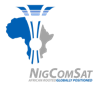 &nbsp;&nbsp; 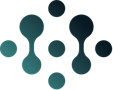

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-4/day-3-feature-engineering/2-exercise/W4D3-exercise.ipynb)

# 👁️ Week 4 · Day 3: Give the Model Eyes

**Today:** the forest can't tell time and can't see "hot for its workload". You build the columns that let it: **history**, **relationships**, and then you cut 32 columns down to 5.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

**Rule book:** keep `W4D3-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _near(x, want, tol):
    return abs(float(x) - want) <= tol

def _c_a1(x):
    ok = isinstance(x, pd.Series) and pd.isna(x.iloc[0]) and float(x.loc["2025-05-02 01:00"]) == 100.0 \
        and float(x.loc["2025-05-02 02:00"]) == 93.2
    return ok, "shift(1): each row now carries the hour before. At 02:00 it remembers 93.2% from 01:00. 🕰️", \
        "Shift by ONE hour into the past: a positive number."

def _c_a2(x):
    ok = isinstance(x, pd.Series) and x.first_valid_index() == pd.Timestamp("2025-01-01 23:00") \
        and 95 < float(x.loc["2025-05-02 12:00"]) < 100
    return ok, "A 24-hour trailing average. The first 23 rows are empty: not enough history yet.", \
        "One day of hourly rows is how many rows?"

def _c_a3(x):
    got = {str(v).strip().lower() for v in x}
    return got == {"b", "d"}, "b and d cheat. At midnight on 2 May nothing had gone wrong yet, but both already 'knew'. 🗞️", \
        "Look at the printed values at 00:00: which columns already show the fault that starts at 01:00?"

def _c_a4(x):
    return int(x) == 24, "24 rows: the longest window is 24 hours, so the first day has no full history.", \
        "Rows in bus minus rows in F: len(bus) - len(F)"

def _c_b1(x):
    ok = isinstance(x, pd.Series) and np.allclose(x.values, (bus["twta_temp_c"] / bus["rf_drive_pct"]).values)
    return ok, "temp_per_drive: degrees per % of drive. How hot it runs FOR ITS WORKLOAD. 🔗", \
        "Temperature divided by drive: bus[\"twta_temp_c\"] / bus[\"rf_drive_pct\"]"

def _c_b2(x):
    ok = isinstance(x, dict) and x.get("caught") == 1 and x.get("false_alarms") == 0
    return ok, "One column, a Week 3 chart: EV04 caught, ZERO false alarms all year. 👁️", \
        "K is the classic number of standard deviations: 3."

def _c_b3(x):
    return int(x) == 605, "605 of 672 hours: the alarm stays on while the fault lasts, not one lucky blip.", \
        "Read hours_flagged in the EV04 row of the table above."

def _c_b4(x):
    return int(x) == 2208, "Every one of the 2,208 Oct–Dec hours. Huge sigma on the fault, useless in service. 🪤", \
        "resid_flags.loc[\"2025-10-01\":].sum()"

def _c_b5(x):
    return x is False or str(x).strip().lower() == "false", \
        "False! Check a feature on months it never saw. The humble 3.9σ ratio stays quiet; the 29σ one cries wolf.", \
        "Did the 29-sigma feature stay quiet in October?"

def _c_c1(x):
    return int(x) == 18, "18 pairs above 0.98. Each twin doubles a sensor's vote in the forest. 👯", \
        "The pruning line from the slides: 0.98"

def _c_c2(x):
    ok = isinstance(x, dict) and x.get("events") == 5 and x.get("caught") == 3 and 40 <= x.get("false_alarms", -1) <= 120
    return ok, f"Only {x.get('caught')} of 5, and {x.get('false_alarms')} false alarms. 32 columns drowned the obvious dropouts.", \
        "contamination is a share of hours: half a percent is 0.005"

def _c_c3(x):
    r = score_events(x, labels)
    lit = int(x.loc["2025-09-03":"2025-09-30 23:00"].sum())
    ok = r["caught"] == 5 and 20 <= r["false_alarms"] <= 80 and lit > 200
    return ok, f"5 of 5, {r['false_alarms']} false alarms, {lit} EV04 hours lit. Fewer, sharper eyes. 🎯", \
        "Fit on the reference: training months AND steady sun: train & steady"

def _c_c4(x):
    return str(x).strip() == "temp_per_drive", "temp_per_drive, every time. Right answer, right reason. 🧑🏾‍🔧", \
        "Copy the column name at the top of the counts, in quotes."

def _c_c5(x):
    return x is False or str(x).strip().lower() == "false", \
        "False. It trained on Jan–Aug, so EV01–EV03 were in its homework. Next time: an honest exam. ⚖️", \
        "Which months did the forest train on? Which events sit in those months?"

def _c_bonus(x):
    ok = isinstance(x, dict) and x.get("caught") == 5 and x.get("false_alarms") == 3
    return ok, "5 of 5 with only 3 false alarms. Keep that result secret until Week 5 Day 1… 🤫🌶️", \
        "Same fit rows as the forest: train & steady"

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "A4": _c_a4, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4,
          "B5": _c_b5, "C1": _c_c1, "C2": _c_c2, "C3": _c_c3, "C4": _c_c4, "C5": _c_c5, "BONUS": _c_bonus}
HINTS = {"A3": "A set of letters, e.g. {\"a\", \"c\"}.", "C3": "Run the toolbox cell first (Part B)."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


---
# Part A: The model cannot tell time (15 min) 🕰️

▶️ Load the year of hourly telemetry (6 sensors + the eclipse flag) and the Week 5 answer key.

In [ ]:
bus = pd.read_csv(data_path("bus_telemetry_multivariate_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
labels = load_labels("anomaly_labels_week5")
print("hours:", len(bus), "· columns:", list(bus.columns))
display(labels[["event_id", "start", "end", "type", "channels_involved"]])

### 💡🔋 NEPA brought light, but the inverter isn't charging
▶️ EV02, 2 May. The sun is shining (`eclipse_flag` is 0) and array current is only a little low, yet state of charge drops to about 93% and stays there.
(The original code book looked at **1 May** by mistake: that day the battery was a normal 100%.)

In [ ]:
bus.loc["2025-05-02 00:00":"2025-05-02 14:00", ["solar_array_current_a", "battery_soc_pct", "bus_voltage_v", "eclipse_flag"]]

### A1 ✍️ History feature 1: the lag
The forest judges **one row at a time**: it has no idea what happened an hour ago. A **lag** copies an older value onto today's row.
`soc.shift(n)` moves the series `n` hours later. Fill in `HOURS_BACK` so the new column means *"state of charge one hour ago"*.

In [ ]:
soc = bus["battery_soc_pct"]
HOURS_BACK = ___

assert HOURS_BACK is not None, "✍️ Fill in HOURS_BACK first, then run this cell again."
soc_lag1 = soc.shift(HOURS_BACK)

print(pd.DataFrame({"soc": soc, "soc_1h_ago": soc_lag1}).loc["2025-05-02 00:00":"2025-05-02 03:00"])
check("A1", soc_lag1)

### A2 ✍️ History feature 2: the rolling mean
A **rolling window** summarises the last few rows, ending at the current one. Fill in `WINDOW`: how many hourly rows make **one day**?

In [ ]:
WINDOW = ___

assert WINDOW is not None, "✍️ Fill in WINDOW first."
soc_mean24 = soc.rolling(WINDOW).mean()

print("first hour with a full window:", soc_mean24.first_valid_index())
print("average of the last day at 2 May 12:00:", round(soc_mean24.loc["2025-05-02 12:00"], 2))
check("A2", soc_mean24)

### A3 ✍️ The 14:00 test
Ask of every feature: ***"Could I compute this at 14:00, using only what I knew at 14:00?"***
▶️ Four candidate features, printed at **midnight on 2 May**, one hour **before** EV02 began. Which of them already "know" about the fault?

In [ ]:
candidates = pd.DataFrame({
    "a": soc.shift(1),
    "b": soc.shift(-1),
    "c": soc.rolling(24).mean(),
    "d": soc.rolling(24, center=True).mean(),
})
candidates.loc["2025-05-01 23:00":"2025-05-02 01:00"].round(2)

In [ ]:
cheaters = ___        # a set of letters, e.g. {"a", "c"}

check("A3", cheaters)

### A4 ✍️ The code book's feature builder
▶️ The original builder makes lags, differences and 24-hour rolling statistics for 4 sensors, plus a few extras. Every window is trailing. Run it.

In [ ]:
def make_features(df):
    """The original code book's builder. Trailing windows only, positive shifts only."""
    f = pd.DataFrame(index=df.index)
    for c in ["solar_array_current_a", "battery_soc_pct", "twta_temp_c", "bus_voltage_v"]:
        f[c]             = df[c]
        f[f"{c}_lag1"]   = df[c].shift(1)
        f[f"{c}_lag24"]  = df[c].shift(24)
        f[f"{c}_d1"]     = df[c].diff(1)
        f[f"{c}_mean24"] = df[c].rolling(24).mean()
        f[f"{c}_std24"]  = df[c].rolling(24).std()
        f[f"{c}_dev24"]  = df[c] - f[f"{c}_mean24"]
    f["temp_per_drive"] = df["twta_temp_c"] / df["rf_drive_pct"]     # relationship
    f["soc_gap"]        = 100 - df["battery_soc_pct"]                 # ... a twin of battery_soc_pct
    f["eclipse_flag"]   = df["eclipse_flag"]                          # known physics
    f["hour"]           = df.index.hour
    return f.dropna()

F = make_features(bus)
print("feature matrix:", F.shape)

✍️ The data has 8,760 hours. How many rows did the builder lose, and why? (`dropna()` removed every row that had an empty window.)

In [ ]:
rows_lost = ___

print("rows lost:", rows_lost)
check("A4", rows_lost)

---
# Part B: Hot for its workload (20 min) 🔗

EV04, 3–30 September: the amplifier's cooling path degraded. For four weeks it ran about 3 °C hot **for its drive level**.

### B1 ✍️ Build the relationship
Amplifier temperature divided by RF drive: *degrees per percent of drive*. Fill in the formula.

In [ ]:
temp_per_drive = ___

assert temp_per_drive is not None, "✍️ Fill in the formula first."
print(temp_per_drive.describe().round(4))
check("B1", temp_per_drive)

### 🧰 The toolbox
▶️ This cell defines today's helpers: the **scorer** (Week 4 Day 1's rules), `event_table()` (caught? how late? how many hours lit?), `steady_sun()` from last time, `lean_features()`, `chart_flags()` and `forest_flags()`. Read them: each is a few lines.
`train` = the reference months, **January to August**.

In [ ]:
from sklearn.ensemble import IsolationForest

def score_events(flags, labels, tol="1h"):
    """Event-level scoring, the same 4 rules as Week 4 Day 1. flags: a True/False Series with a time index.
    Events that fall outside the hours being scored are skipped."""
    tol = pd.Timedelta(tol)
    n_events, caught, inside_any = 0, 0, pd.Series(False, index=flags.index)
    for _, ev in labels.iterrows():
        window = (flags.index >= ev["start"] - tol) & (flags.index <= ev["end"] + tol)
        if not window.any():
            continue                     # this event is not in the hours being scored
        n_events += 1
        if flags[window].any():          # one flag or many = ONE catch
            caught += 1
        inside_any |= window
    false_alarms = int((flags & ~inside_any).sum())
    alarms = caught + false_alarms
    return {"events": n_events, "caught": caught, "false_alarms": false_alarms,
            "recall": round(caught / n_events, 3) if n_events else float("nan"),
            "precision": round(caught / alarms, 3) if alarms else float("nan")}

def event_table(flags, labels):
    """One row per event: caught? how many hours late was the first flag? how many of its hours lit up?"""
    rows = []
    for _, ev in labels.iterrows():
        inside = (flags.index >= ev["start"]) & (flags.index <= ev["end"])
        if not inside.any():
            continue
        window = (flags.index >= ev["start"] - pd.Timedelta("1h")) & (flags.index <= ev["end"] + pd.Timedelta("1h"))
        hits = flags[window]
        first = hits[hits].index.min() if hits.any() else None
        rows.append({"event": ev["event_id"], "type": ev["type"], "caught": bool(hits.any()),
                     "hours_late": None if first is None else int((first - ev["start"]) / pd.Timedelta("1h")),
                     "hours_flagged": int(flags[inside].sum()), "hours_long": int(inside.sum())})
    return pd.DataFrame(rows).set_index("event").astype({"hours_late": "Int64"})

def steady_sun(bus):
    """True in steady sunlight: no eclipse this hour or in the 3 hours before.
    Eclipse (battery power) and the 3 recharge hours after it are normal states with their own normal."""
    return bus["eclipse_flag"].rolling(4).max() == 0

def lean_features(bus):
    """Four health channels plus ONE relationship: amplifier temperature per % of RF drive."""
    X = bus[["solar_array_current_a", "bus_voltage_v", "battery_soc_pct", "battery_temp_c"]].copy()
    X["temp_per_drive"] = bus["twta_temp_c"] / bus["rf_drive_pct"]
    return X

def chart_flags(X, fit_rows, judge_rows, k=3):
    """Week 4 control chart on every column: flag the hour if ANY column is more than k sigma from its normal."""
    ref = X[fit_rows]
    z = (X - ref.mean()) / ref.std()
    return (z.abs() > k).any(axis=1) & judge_rows

def forest_flags(X, fit_rows, judge_rows, contamination=0.005, seed=42):
    """Isolation forest, fitted on the reference rows only, judging the chosen rows."""
    model = IsolationForest(n_estimators=200, contamination=contamination, random_state=seed)
    model.fit(X[fit_rows])
    return pd.Series(model.predict(X) == -1, index=X.index) & judge_rows

steady = steady_sun(bus)
print("✅ toolbox ready ·", int(steady.sum()), "steady-sun hours of", len(bus))

train = bus.index < "2025-09-01"          # the reference months: January to August

▶️ First the old way: 3σ on the **raw** amplifier temperature (limits from January–August, steady sun).

In [ ]:
twta = bus["twta_temp_c"]
ref_t = twta[train & steady]
ceiling = ref_t.mean() + 3 * ref_t.std()
print(f"3-sigma ceiling: {ceiling:.2f} C  ·  hottest EV04 hour: {twta.loc['2025-09-03':'2025-09-30'].max():.2f} C")

twta.plot(title="Raw amplifier temperature: four weeks of EV04, zero alarms", lw=.6)
plt.axhline(ceiling, color="#E5484D", ls="--"); plt.axvspan("2025-09-03", "2025-10-01", color="#C77700", alpha=.18); plt.show()

### B2 ✍️ A Week 3 chart on the new column
Same 3σ idea, but on `temp_per_drive`, with the normal learned from the training months. How many standard deviations wide is the band?

In [ ]:
assert temp_per_drive is not None, "✍️ Finish B1 first."
ref = temp_per_drive[train]
z_tpd = (temp_per_drive - ref.mean()) / ref.std()

K = ___

assert K is not None, "✍️ Fill in K first."
tpd_flags = z_tpd.abs() > K
tpd_result = score_events(tpd_flags, labels)
print(f"normal: {ref.mean():.3f} ± {ref.std():.3f}  ·  ceiling {ref.mean() + K * ref.std():.3f}")
print(tpd_result)
check("B2", tpd_result)

▶️ The picture, and the event table: was it caught, how many hours late, and how many of its hours lit up?

In [ ]:
assert "tpd_flags" in globals(), "✍️ Finish B2 first."
temp_per_drive.plot(title="temp_per_drive: EV04 jumps out", lw=.6)
plt.axhline(ref.mean() + 3 * ref.std(), color="#E5484D", ls="--"); plt.axvspan("2025-09-03", "2025-10-01", color="#C77700", alpha=.18); plt.show()
event_table(tpd_flags, labels)

### B3 ✍️ A real catch, not a lucky blip
Last time the forest noticed EV04 on **1** hour. How many of EV04's 672 hours does this one column light up? Read it from the table.

In [ ]:
ev04_hours_lit = ___

check("B3", ev04_hours_lit)

### 🪤 The 29σ trap
▶️ The original code book builds a cleverer feature: an **expected** temperature from drive level and the season (sin/cos of the day of year), fitted on **January to May**, then the residual = actual − expected. Look how far out EV04 sits… then look at the rest of the year.

In [ ]:
from sklearn.linear_model import LinearRegression

doy = bus.index.day_of_year
design = pd.DataFrame({"drive": bus["rf_drive_pct"], "sin": np.sin(2 * np.pi * doy / 365),
                       "cos": np.cos(2 * np.pi * doy / 365)}, index=bus.index)
fit = bus.index < "2025-06-01"                     # the code book fits on January to May
expected = LinearRegression().fit(design[fit], twta[fit]).predict(design)
resid = twta - expected
resid_sd = resid[fit].std()
ev04_sigma = (resid.loc["2025-09-03":"2025-09-30"].mean() - resid[fit].mean()) / resid_sd
print(f"residual spread Jan-May: {resid_sd:.3f} C  ·  EV04 sits {ev04_sigma:.1f} sigma out")

resid_flags = (resid - resid[fit].mean()).abs() > 3 * resid_sd
resid.plot(title="The code book residual: fitted Jan-May, carried to December", lw=.6)
plt.axhspan(resid[fit].mean() - 3 * resid_sd, resid[fit].mean() + 3 * resid_sd, color="#9DB0C6", alpha=.3)
plt.axvspan("2025-09-03", "2025-10-01", color="#C77700", alpha=.18); plt.show()
print(score_events(resid_flags, labels))

### B4 ✍️ How many October–December hours does it flag?
`resid_flags` is True for every hour outside the ±3σ band. Count the ones from 1 October onwards.

In [ ]:
octdec_flagged = ___

print(octdec_flagged, "of", len(resid_flags.loc["2025-10-01":]), "hours")
check("B4", octdec_flagged)

### B5 ✍️ True or False?
*"A feature that puts the fault 29σ out is always better than one that puts it 4σ out."* Answer `True` or `False` (no quotes).

In [ ]:
big_sigma_always_wins = ___

check("B5", big_sigma_always_wins)

---
# Part C: Fewer, better eyes (20 min) ✂️

### C1 ✍️ Find the twins
▶️ + ✍️ The code book's 32 columns, every pair ranked by how alike they are. Pairs above about **0.98** are duplicates. Fill in that cutoff.

In [ ]:
c = F.corr().abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print(pairs.head(6).round(3))

CUTOFF = ___

assert CUTOFF is not None, "✍️ Fill in CUTOFF first."
n_twins = int((pairs > CUTOFF).sum())
print("pairs above the cutoff:", n_twins)
check("C1", n_twins)

### C2 ✍️ The kitchen-sink forest
Fit the forest on all 32 columns (reference = training months in steady sun) and score the whole year. Last time we let it flag **half a percent** of hours. Fill that in as a fraction. (Takes a few seconds.)

In [ ]:
sink_steady = steady.reindex(F.index)
sink_train = pd.Series(train, index=bus.index).reindex(F.index)

CONTAMINATION = ___

assert CONTAMINATION is not None, "✍️ Fill in CONTAMINATION first."
sink_flags = forest_flags(F, sink_train & sink_steady, sink_steady, contamination=CONTAMINATION).reindex(bus.index, fill_value=False)
sink_result = score_events(sink_flags, labels)
print(sink_result)
check("C2", sink_result)

### C3 ✍️ The lean five
▶️ `lean_features(bus)` keeps four health sensors and adds **one** relationship, `temp_per_drive`. (RF drive and raw temperature drift with the load and the seasons, so they stay out.)
✍️ Set `FIT_ROWS` to the **reference rows**: the training months **and** steady sun.

In [ ]:
X = lean_features(bus)
print(list(X.columns))

FIT_ROWS = ___

assert FIT_ROWS is not None, "✍️ Fill in FIT_ROWS first."
lean_flags = forest_flags(X, FIT_ROWS, steady)

lean_result = score_events(lean_flags, labels)
print(lean_result)
check("C3", lean_flags)

▶️ Side by side, event by event.

In [ ]:
assert "sink_flags" in globals() and "lean_flags" in globals(), "✍️ Finish C2 and C3 first."
pd.concat({"kitchen sink (32)": event_table(sink_flags, labels)[["caught", "hours_late", "hours_flagged"]],
           "lean 5": event_table(lean_flags, labels)[["caught", "hours_late", "hours_flagged"]]}, axis=1)

### C4 ✍️ Right answer, right reason
A flag with no reason won't survive the duty engineer. **z-score** = how many σ a feature sits from its normal (training months, steady sun).
▶️ + ✍️ For EV04's flagged hours, which feature has the biggest |z| most often?

In [ ]:
assert "lean_flags" in globals(), "✍️ Finish C3 first."
ref_x = X[train & steady]
z = (X - ref_x.mean()) / ref_x.std()

ev04_flagged = lean_flags & (bus.index >= "2025-09-03") & (bus.index < "2025-10-01")
print(z[ev04_flagged].abs().idxmax(axis=1).value_counts())

top_reason_ev04 = ___

check("C4", top_reason_ev04)

▶️ The same check for every event: the median z of its flagged hours. Read each row like an engineer.

In [ ]:
assert "z" in globals(), "✍️ Finish C4 first."
reasons = {}
for _, ev in labels.iterrows():
    hours = lean_flags & (bus.index >= ev["start"]) & (bus.index <= ev["end"])
    reasons[ev["event_id"]] = z[hours].median()
pd.DataFrame(reasons).T.round(1)

### C5 ✍️ True or False?
*"5 of 5 on the whole year is an honest exam score for this forest."* Think about which months it trained on. Answer `True` or `False`.

In [ ]:
honest_exam = ___

check("C5", honest_exam)

---
## 🌶️ Pepper task: race the old chart
Give the **Week 4 control chart** the same five eyes: `chart_flags()` flags an hour if **any** column is more than 3σ from its normal. Set `CHART_FIT_ROWS` to the same reference rows as the forest. Who wins on the whole year?

In [ ]:
CHART_FIT_ROWS = ___

assert CHART_FIT_ROWS is not None, "✍️ Fill in CHART_FIT_ROWS first."
chart_lean = chart_flags(X, CHART_FIT_ROWS, steady)

chart_result = score_events(chart_lean, labels)
print("forest:", lean_result)
print("chart: ", chart_result)
check("BONUS", chart_result)

---
## 🏁 Final project · Checkpoint 3: 🛠️ Method drafted
Tick these off with your trainer today (on **your** data, on NIGCOMSAT systems, not in Colab):

- [ ] The **minimum method** for your brief runs end to end on your data (detection: a statistical baseline **plus** a multivariate detector on trailing features · degradation/capacity: a trend-to-threshold estimate · forecasting: a baseline forecast **plus** a regression)
- [ ] Your **"normal" in writing**: the states or modes (eclipse, rain, weekend…) and what you take away first (season, drive level…)
- [ ] Your **features** listed, each passing the **14:00 test**, at least one carrying history or a relationship
- [ ] Your **reference period**: months your unit agrees were quiet, written down
- [ ] The **simple baseline** you will race next checkpoint
- [ ] Raw data **not** on GitHub; nothing restricted pasted into an AI tool

Next checkpoint: **Week 5 · Day 3: honest test** ⚖️ (split by time + a baseline comparison table)

## Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **The model cannot tell time.** Lags (`shift(1)`) and rolling windows (`rolling(24)`) give each row a memory.
- **The 14:00 test:** past only. `shift(-1)` and `center=True` read tomorrow's newspaper.
- **One relationship column** (`temp_per_drive`) turned four invisible weeks into 605 lit hours with zero false alarms.
- **A big sigma is not the test.** The 29σ feature flagged every Oct–Dec hour. Check features on months they never saw.
- **Fewer, sharper features:** prune twins above 0.98; 5 good columns caught what 32 missed.
- **Explain every flag** with z-scores: right answer, right reason.

**Next time:** *No expo! Honest train/test splits + Quiz 3.* ⚖️

<sub>Data: synthetic teaching datasets from the original Week 5 code book (`Time-series/week-05`). Safe to use with AI tools; real NIGCOMSAT data is not.</sub>